# SISPS-BATT-INT-CAL Oscilloscope

Oscilloscope measurements of the SISPS Battery Interposer for Lead Acid Battery Freezing Extent Measurement for verification of the impedance measurement method.

## Setup

In [55]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

from matplotlib.ticker import FuncFormatter
from matplotlib.figure import Figure
from matplotlib.axes import Axes

from cycler import cycler

import re

from concurrent.futures import ThreadPoolExecutor

from typing import List, Tuple, Dict, Any

In [56]:
PLOT_OUTPUT_DIR = "../Plots"
os.makedirs(PLOT_OUTPUT_DIR, exist_ok=True)

In [57]:
plt.rcParams.update(
    {
        "figure.dpi": 600,
    }
)
# plt.rcParams["axes.prop_cycle"] = cycler(color=plt.get_cmap("tab20").colors)  # type: ignore

## Data Import

In [58]:
SCOPE_DATA_PATH = "../Data/Oscilloscope/Data"
# SCOPE_IMG_PATH = "../Data/Oscilloscope/Images"

In [59]:
def find_scope_files(directory: str) -> List[str]:
    """
    Find all CSV files in the specified directory.

    Parameters:
        directory (str): The path to the directory to search for CSV files.

    Returns:
        List[str]: A list of file paths to the found CSV files.
    """
    return [
        os.path.join(directory, file)
        for file in os.listdir(directory)
        if file.endswith(".csv")
    ]


def load_scope_data(file_path: str) -> pd.DataFrame:
    """
    Load oscilloscope data from a CSV file.

    Parameters:
        file_path (str): The path to the CSV file containing the oscilloscope data.

    Returns:
        pd.DataFrame: A DataFrame containing the loaded oscilloscope data.
    """
    HEADER_ROWS = 68

    def dict_metadata(metadata_str: str) -> Dict[str, Any]:
        metadata = {}
        for line in metadata_str.splitlines():
            if "," in line:
                key, value = line.split(",")
                metadata[key.strip()] = value.strip()
        return metadata

    def get_metadata(name: str, header_lines: str) -> Dict[str, Any]:
        """
        Extract metadata for a specific channel from the header.
        Parameters:
            channel_num (int): The channel number to extract metadata for.
            header_lines (str): The header lines from the CSV file.

        Returns:
            Dict[str, Any]: A dictionary containing the extracted metadata.
        """
        params = re.search(
            rf"{name}\n(.*?)(?:\n\n|$)",
            header_lines,
            re.DOTALL,
        )
        if not params:
            raise ValueError(f"'{name}' metadata not found in header.")

        # Metadata is name,value pairs separated by a comma
        metadata = dict_metadata(params.group(1))
        return metadata

    print(f"Loading data from {file_path}...")

    df = pd.read_csv(file_path, skiprows=HEADER_ROWS)
    with open(file_path, "r") as f:
        header = "\n".join(f.read().splitlines()[:HEADER_ROWS])

    idMatch = re.match(r".*-T(\d\d)-C(\d\d).*\.csv", os.path.basename(file_path))
    if not idMatch:
        raise ValueError(f"Filename {file_path} does not match expected pattern.")

    df.attrs = {
        "Test": idMatch.group(1),
        "Battery": idMatch.group(2),
        "Channel 1": get_metadata("Channel 1", header),
        "Channel 2": get_metadata("Channel 2", header),
        "Channel 3": get_metadata("Channel 3", header),
        "Channel 4": get_metadata("Channel 4", header),
        "Math 1": get_metadata("Math 1", header),
        "Trigger": get_metadata("Trigger", header),
    }

    print(f"Loaded data for T{df.attrs['Test']}, C{df.attrs['Battery']}.")

    return df


scope_dfs = [load_scope_data(file) for file in find_scope_files(SCOPE_DATA_PATH)]
scope_dfs.sort(key=lambda df: int(df.attrs["Test"]))

Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T13-C13-EIS.csv...
Loaded data for T13, C13.
Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T09-C09-EIS.csv...
Loaded data for T09, C09.
Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T03-C03-EIS.csv...
Loaded data for T03, C03.
Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T10-C10-EIS.csv...
Loaded data for T10, C10.
Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T04-C04-EIS.csv...
Loaded data for T04, C04.
Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T14-C14-EIS.csv...
Loaded data for T14, C14.
Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T07-C07-EIS.csv...
Loaded data for T07, C07.
Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T12-C12-EIS.csv...
Loaded data for T12, C12.
Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T01-C01-EIS.csv...
Loaded data for T01, C01.
Loading data from ../Data/Oscilloscope/Data/SISPS-INT-CAL-T08-C08-EIS.csv

## Phase Calculation

In [60]:
PHASE_WINDOW = (0.1, 0.5)


def calculate_phase_difference(df: pd.DataFrame, window: Tuple[float, float]) -> float:
    TIME_MASK = (df["Time(s)"] >= window[0]) & (df["Time(s)"] <= window[1])
    TIME = df["Time(s)"][TIME_MASK]

    VOLTAGE = df["Channel2"][TIME_MASK]
    CURRENT = df["Channel1"][TIME_MASK]

    hanning_window = np.hanning(len(TIME))

    voltage = hanning_window * VOLTAGE
    current = hanning_window * CURRENT

    voltage_spectrum = np.fft.fft(voltage)
    current_spectrum = np.fft.fft(current)

    voltage_phase = np.angle(voltage_spectrum)
    current_phase = np.angle(current_spectrum)

    phase_diff = np.degrees(voltage_phase - current_phase)
    if phase_diff[1] < 0:
        phase_diff[1] += 360

    return phase_diff[1]


phase_differences = [calculate_phase_difference(df, PHASE_WINDOW) for df in scope_dfs]

## RMS Voltage, Current, Impedance Calculation

In [61]:
RMS_WINDOW = (0.1, 0.5)


def calculate_rms(
    series: pd.Series, time: pd.Series, window: Tuple[float, float]
) -> float:
    TIME_MASK = (time >= window[0]) & (time <= window[1])
    signal = series[TIME_MASK]
    rms_value = np.sqrt(np.mean(signal**2))

    return rms_value


CURRENT_GAIN = 5.5  # Current to voltage gain of the instrumentation amplifier
VOLTAGE_GAIN = 10.0  # Voltage gain (assumed to be 1 for direct measurement)

CURRENT_DIFF_P = 2.0  # Volts. Constant differential pair positive. Measured current is CURRENT_DIFF_N

current_rms_values = [
    calculate_rms(CURRENT_DIFF_P - df["Channel1"], df["Time(s)"], RMS_WINDOW)
    / CURRENT_GAIN
    for df in scope_dfs
]
voltage_rms_values = [
    calculate_rms(df["Channel2"], df["Time(s)"], RMS_WINDOW) / VOLTAGE_GAIN
    for df in scope_dfs
]
impedance_values = [
    voltage_rms / current_rms if current_rms > 0 else np.inf
    for voltage_rms, current_rms in zip(voltage_rms_values, current_rms_values)
]

for i in range(len(scope_dfs)):
    print(
        f"T{scope_dfs[i].attrs['Test']}, C{scope_dfs[i].attrs['Battery']}, Phase Difference: {phase_differences[i]:.2f}°, Voltage RMS: {1000*voltage_rms_values[i]:.3f} mV, Current RMS: {1000*current_rms_values[i]:.3f} mA, Impedance: {impedance_values[i]:.6f} Ω"
    )

T01, C01, Phase Difference: 183.22°, Voltage RMS: 0.598 mV, Current RMS: 83.559 mA, Impedance: 0.007156 Ω
T02, C02, Phase Difference: 184.74°, Voltage RMS: 0.574 mV, Current RMS: 82.986 mA, Impedance: 0.006917 Ω
T03, C03, Phase Difference: 184.25°, Voltage RMS: 0.598 mV, Current RMS: 83.803 mA, Impedance: 0.007137 Ω
T04, C04, Phase Difference: 183.99°, Voltage RMS: 0.594 mV, Current RMS: 83.765 mA, Impedance: 0.007092 Ω
T05, C05, Phase Difference: 187.43°, Voltage RMS: 0.629 mV, Current RMS: 83.757 mA, Impedance: 0.007506 Ω
T06, C06, Phase Difference: 185.69°, Voltage RMS: 0.602 mV, Current RMS: 83.715 mA, Impedance: 0.007190 Ω
T07, C07, Phase Difference: 186.29°, Voltage RMS: 0.703 mV, Current RMS: 83.732 mA, Impedance: 0.008399 Ω
T08, C08, Phase Difference: 186.98°, Voltage RMS: 0.702 mV, Current RMS: 83.895 mA, Impedance: 0.008364 Ω
T09, C09, Phase Difference: 199.78°, Voltage RMS: 6.161 mV, Current RMS: 83.539 mA, Impedance: 0.073748 Ω
T10, C10, Phase Difference: 197.21°, Voltage R

In [62]:
import import_ipynb
from Impedance import freezing_extent, VBATT_DATA_PATH, load_vbatt_data  # type: ignore

In [63]:
vbatt = load_vbatt_data(VBATT_DATA_PATH).iloc[:14]

freezing_extent_values = [
    freezing_extent(vbatt_ht, vbatt_lt)
    for vbatt_ht, vbatt_lt in zip(vbatt["VBATT HT"] / 6, vbatt["VBATT LT"] / 6)
]

## Plotting

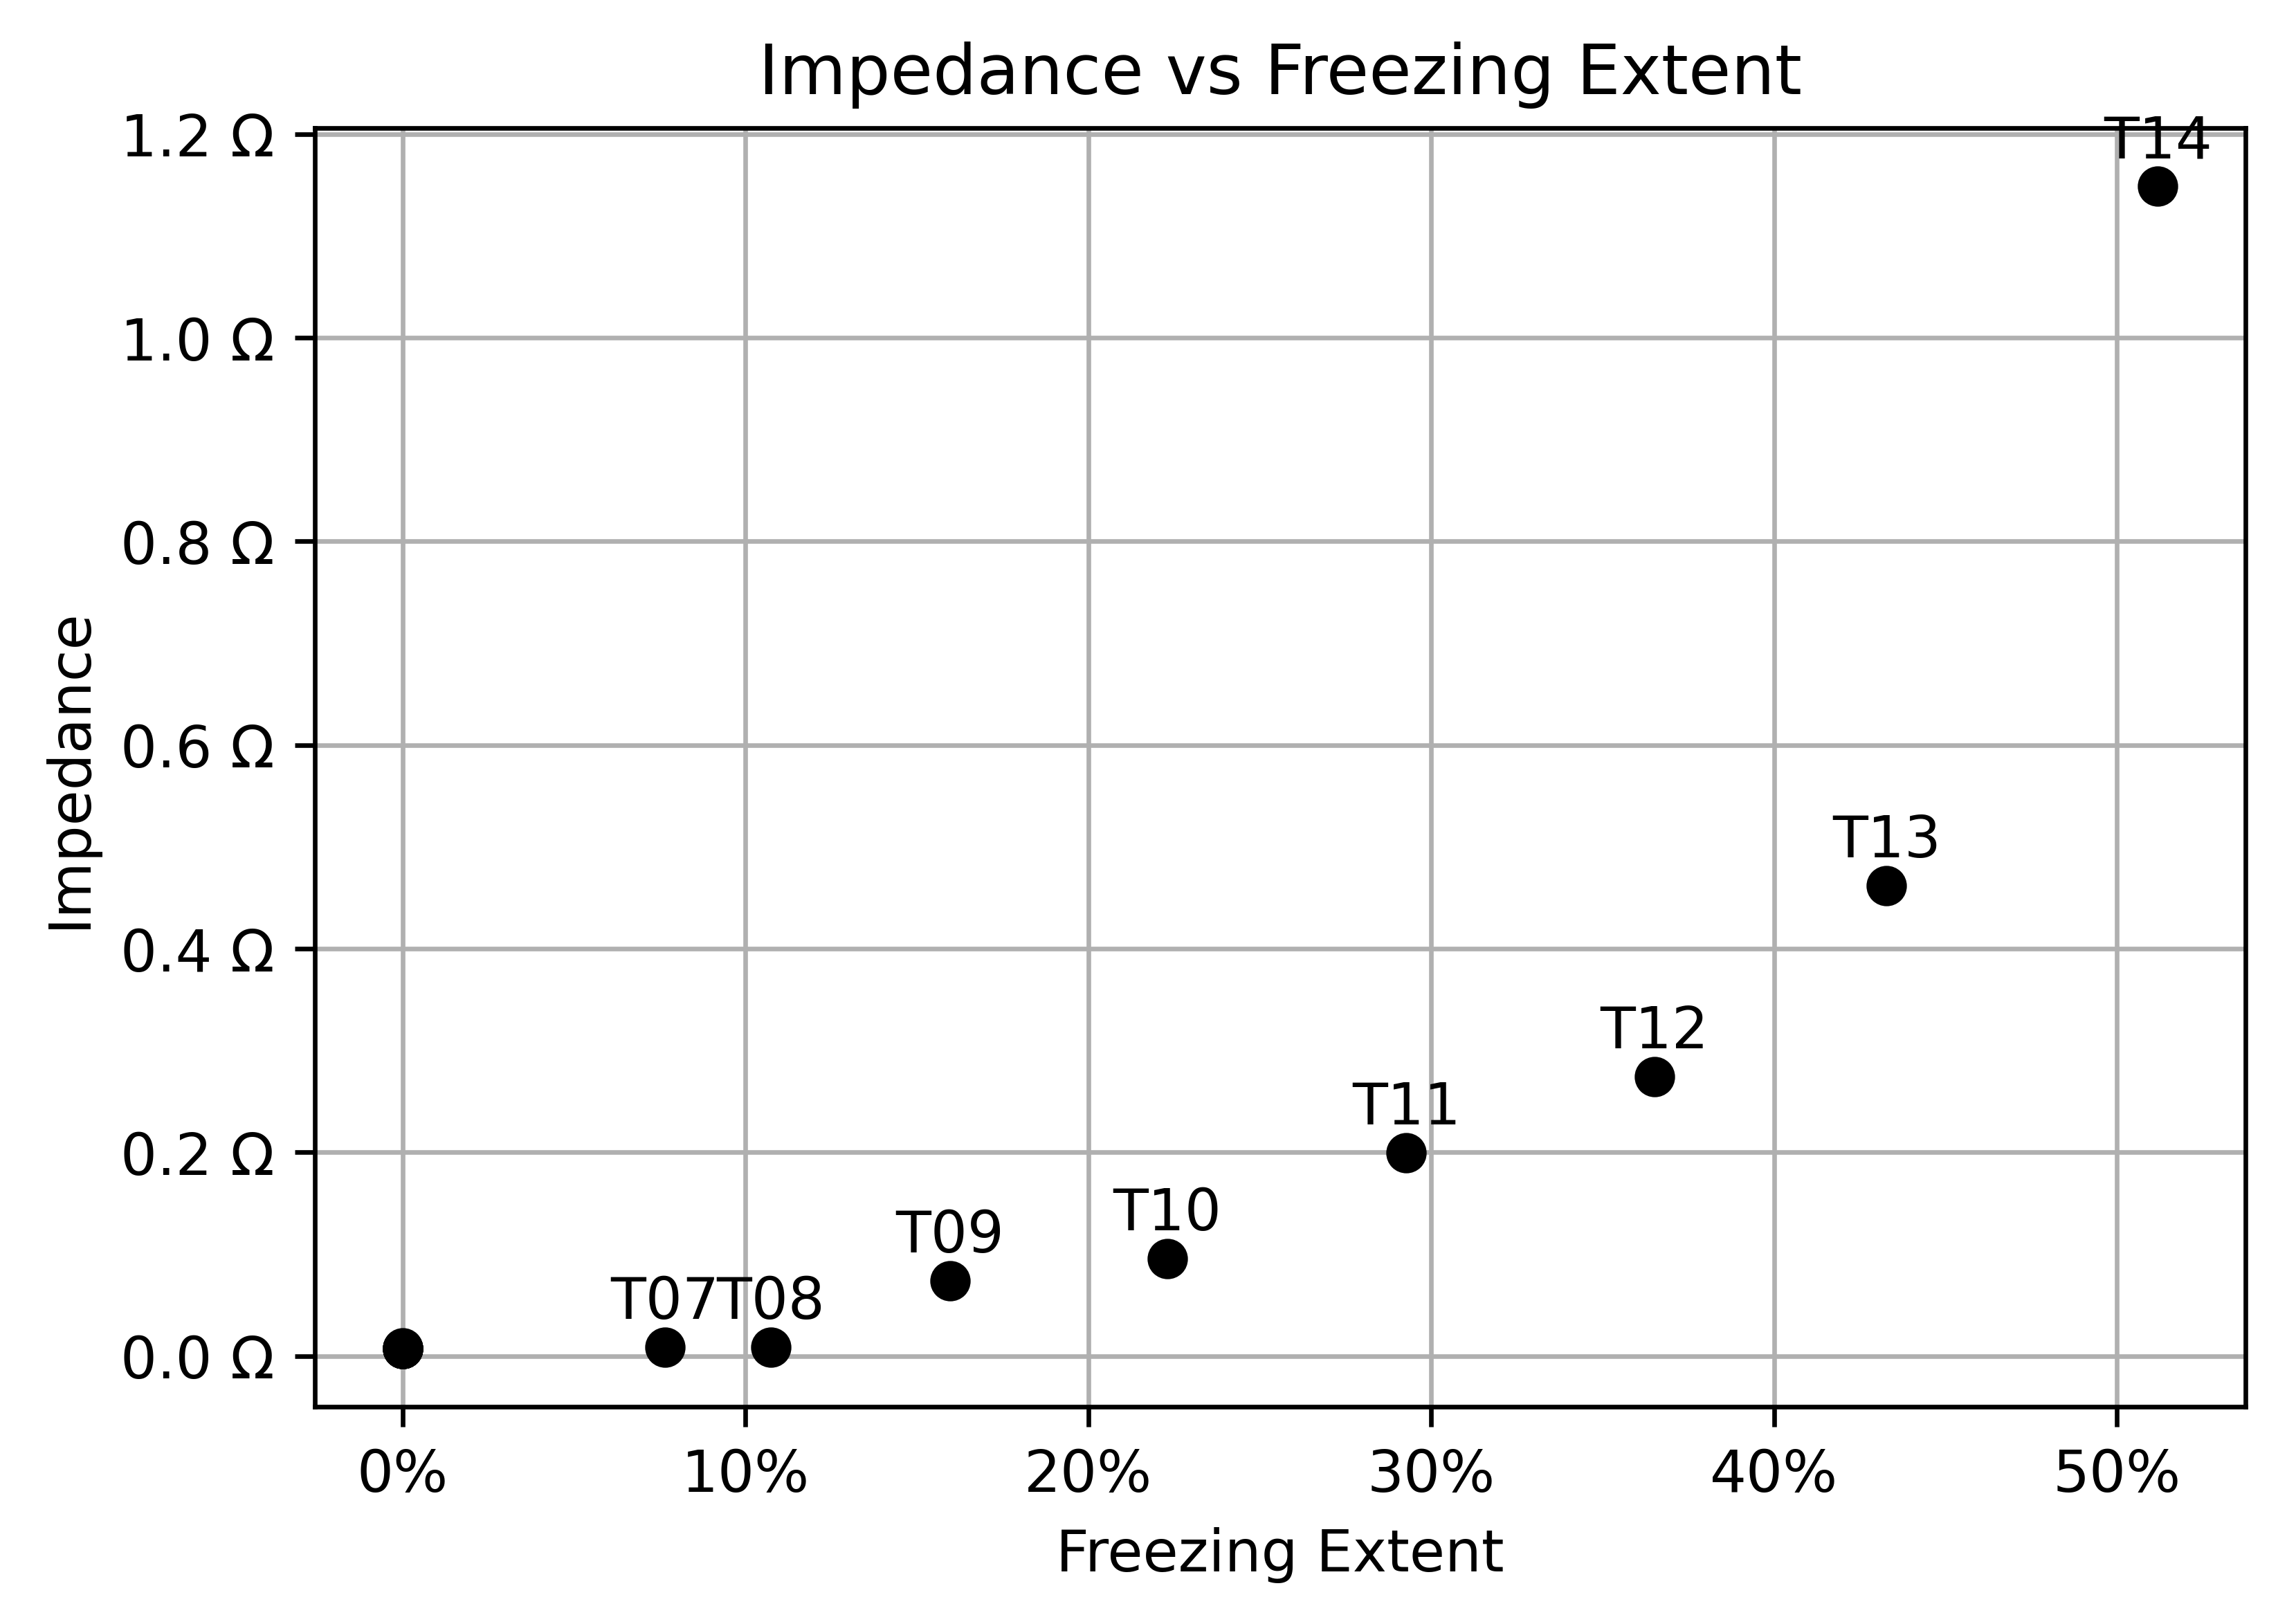

In [64]:
def plot_impedance_vs_freezing_extent(
    impedance_values: List[float],
    freezing_extent_values: List[float],
) -> Figure:
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(
        freezing_extent_values,
        impedance_values,
        marker="o",
        linestyle="",
        color="black",
    )

    for i in range(len(impedance_values)):
        if freezing_extent_values[i] == 0:
            continue
        ax.annotate(
            f"T{i+1:02d}",
            (freezing_extent_values[i], impedance_values[i]),
            textcoords="offset points",
            xytext=(0, 5),
            ha="center",
        )

    ax.set_xlabel("Freezing Extent")
    ax.set_ylabel("Impedance")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.1f} Ω"))

    ax.set_title("Impedance vs Freezing Extent")
    ax.grid(True)
    return fig


_ = plot_impedance_vs_freezing_extent(impedance_values, freezing_extent_values)

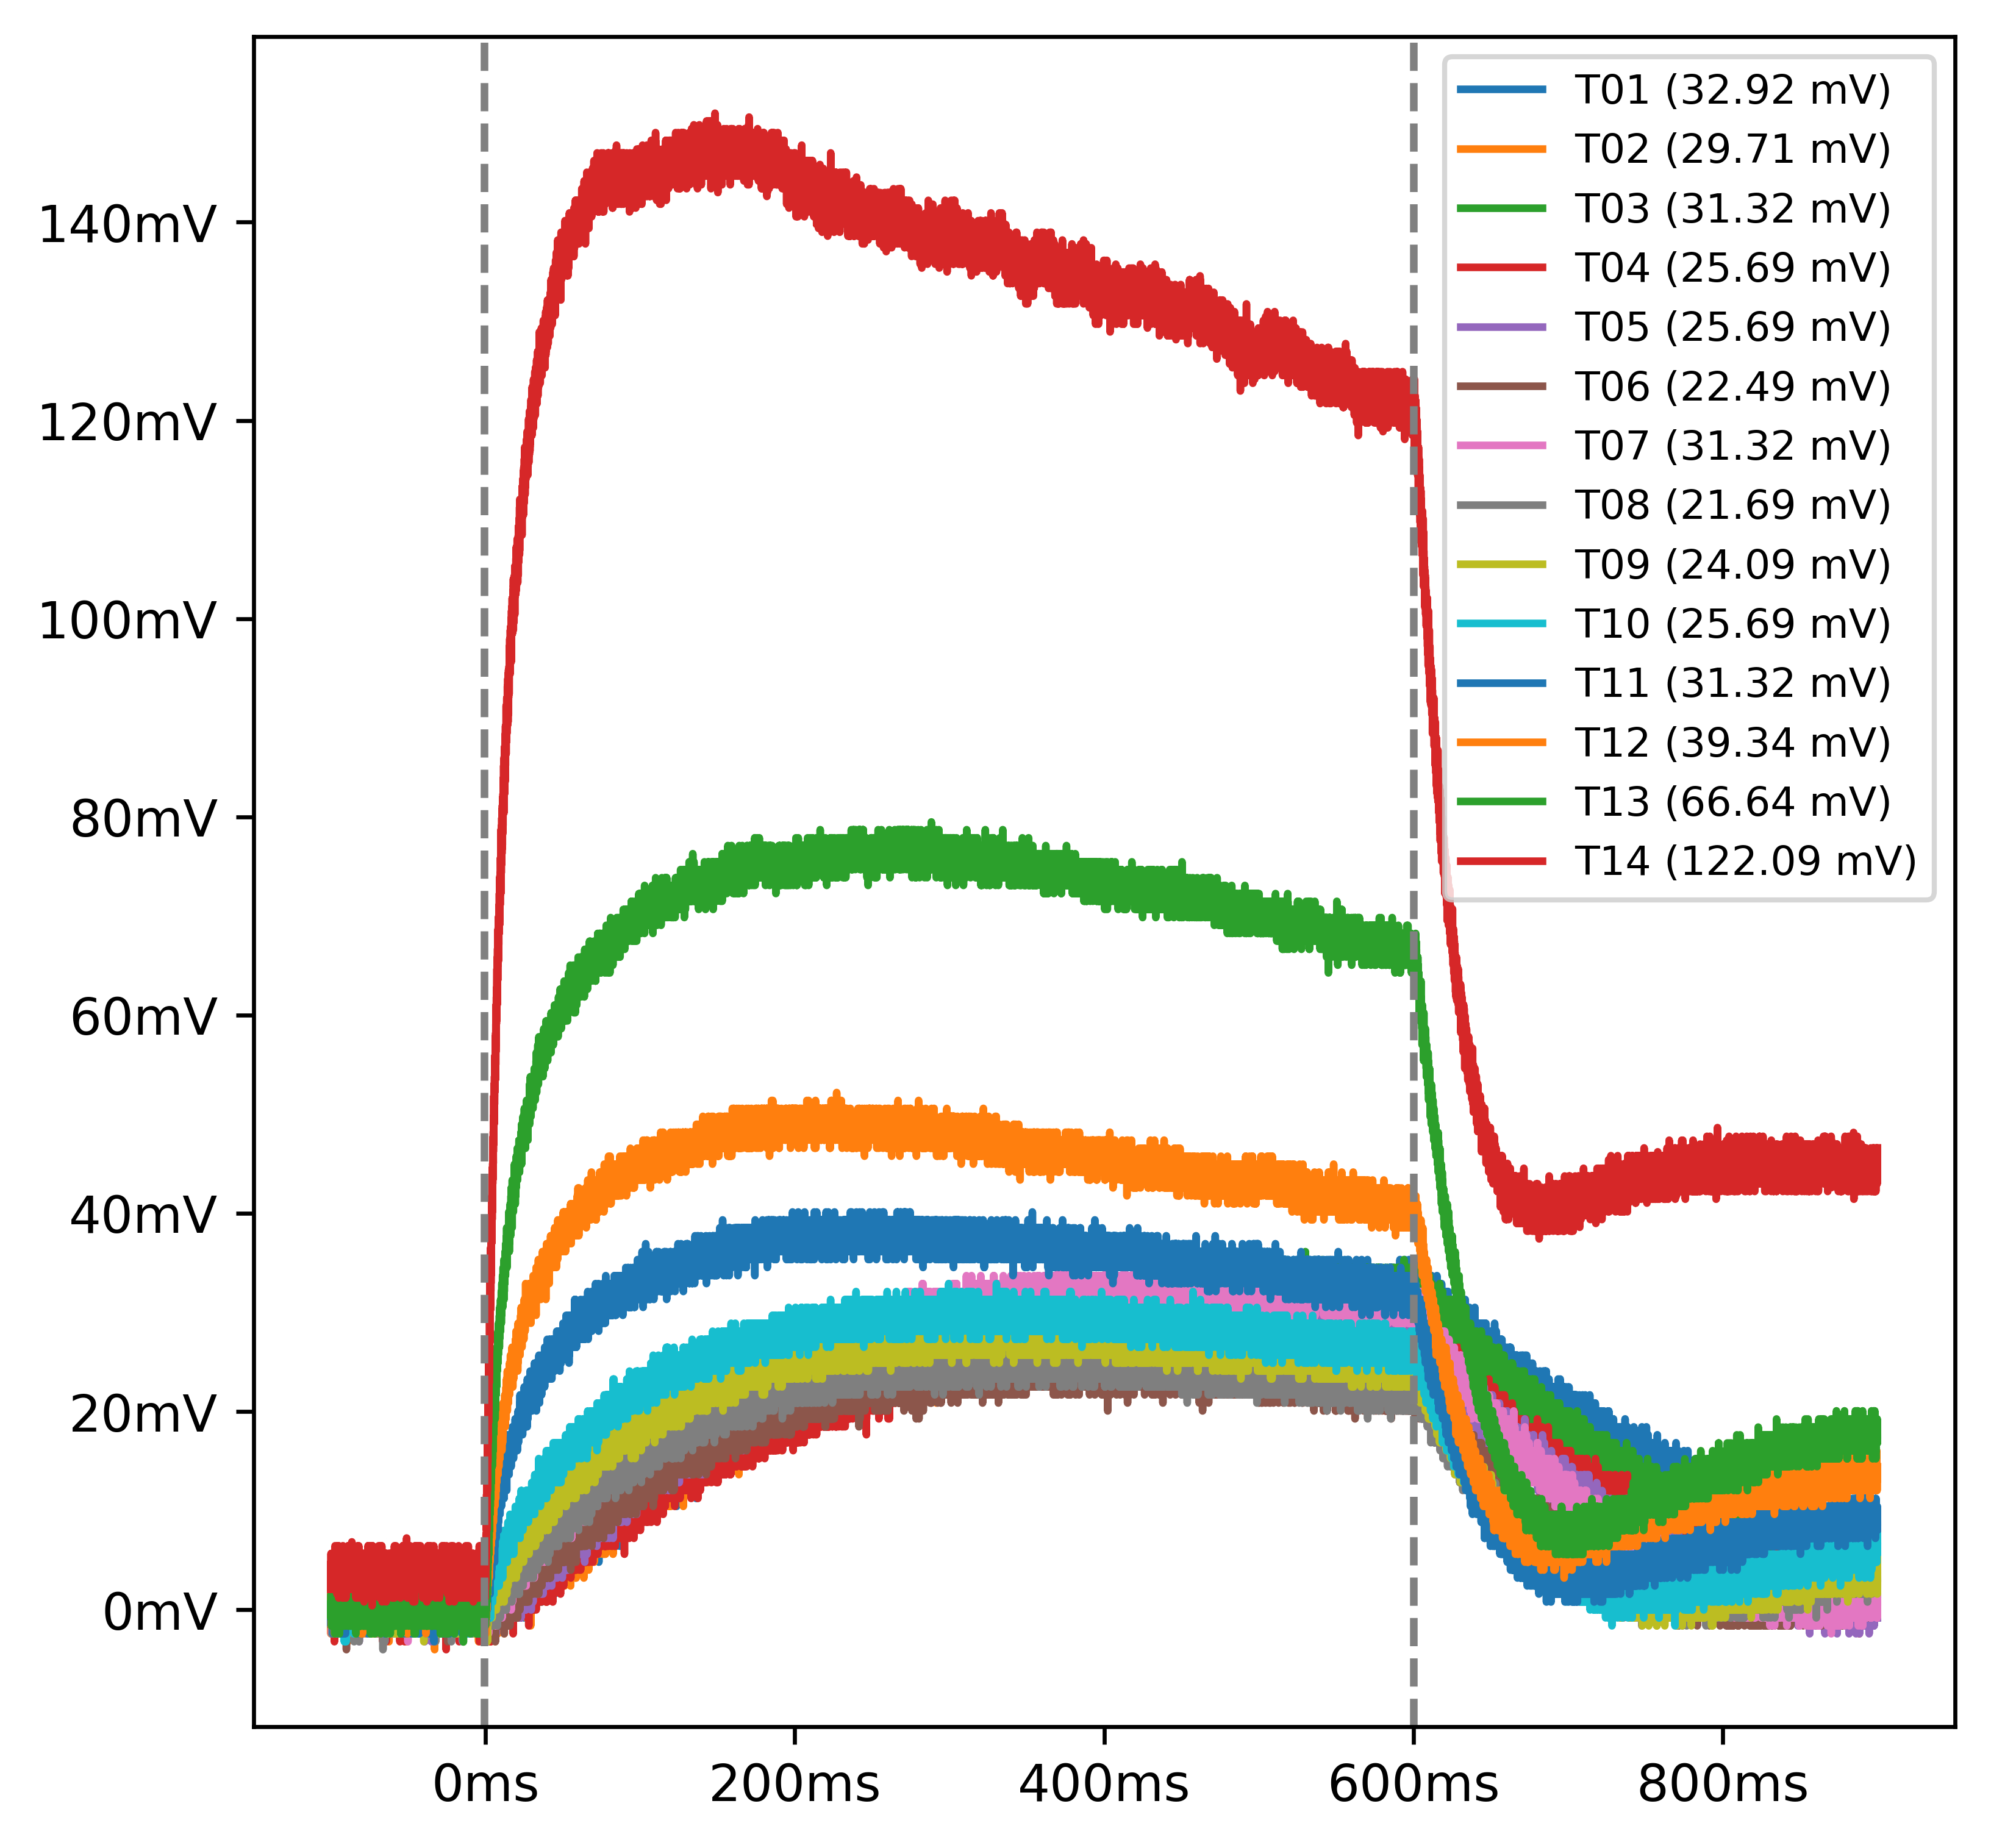

In [65]:
RMS_MEAS_POINT = 0.6  # Fixed constant from initial trigger
RMS_NULL_MEAS_POINT = -0.001  # Point before current starts for null measurement


def get_adc_measurement(
    df: pd.DataFrame, series_name: str, measurement_point: float
) -> float:
    measure_time = (
        df["Time(s)"]
        .iloc[(df["Time(s)"] - measurement_point).abs().argsort()[:1]]
        .values[0]
    )
    measure_value = df[series_name][df["Time(s)"] == measure_time].values[0]
    return measure_value


def get_max_measurement(df: pd.DataFrame, series_name: str) -> float:
    return df[series_name].max()


def plot_math_output(df: pd.DataFrame, ax: Axes) -> None:
    test = df.attrs["Test"]

    measure_value = get_adc_measurement(df, "Math1", RMS_MEAS_POINT)

    ax.plot(
        df["Time(s)"],
        df["Math1"],
        label=f"T{test} ({measure_value*1000:.2f} mV)",
    )


def plot_math_outputs(dfs: List[pd.DataFrame]) -> Figure:
    fig, ax = plt.subplots(figsize=(6, 6))

    for df in dfs:
        plot_math_output(df, ax)

    ax.axvline(RMS_NULL_MEAS_POINT, color="gray", linestyle="--")
    ax.axvline(RMS_MEAS_POINT, color="gray", linestyle="--")

    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{1000*x:.0f}ms"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{1000*y:.0f}mV"))
    ax.legend(fontsize=8)

    return fig


_ = plot_math_outputs(scope_dfs)

In [66]:
RMS_OUTPUT_DIR = os.path.join(PLOT_OUTPUT_DIR, "RMS")
os.makedirs(RMS_OUTPUT_DIR, exist_ok=True)
for i, df in enumerate(scope_dfs):
    fig, ax = plt.subplots(figsize=(6, 6))
    plot_math_output(df, ax)

    ax.axvline(RMS_NULL_MEAS_POINT, color="gray", linestyle="--")
    ax.axvline(RMS_MEAS_POINT, color="gray", linestyle="--")

    rms_max = get_max_measurement(df, "Math1")
    ax.axhline(rms_max, color="gray", linestyle="--")
    ax.annotate(
        f"{rms_max*1000:.2f} mV",
        xy=(0.5, rms_max),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=8,
    )

    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{1000*x:.0f}ms"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{1000*y:.0f}mV"))
    ax.set_title(f"T{df.attrs['Test']}, C{df.attrs['Battery']}")
    ax.legend(fontsize=8)

    plt.savefig(
        os.path.join(
            RMS_OUTPUT_DIR,
            f"T{df.attrs['Test']}_C{df.attrs['Battery']}_math_output.png",
        ),
        bbox_inches="tight",
    )
    plt.close(fig)

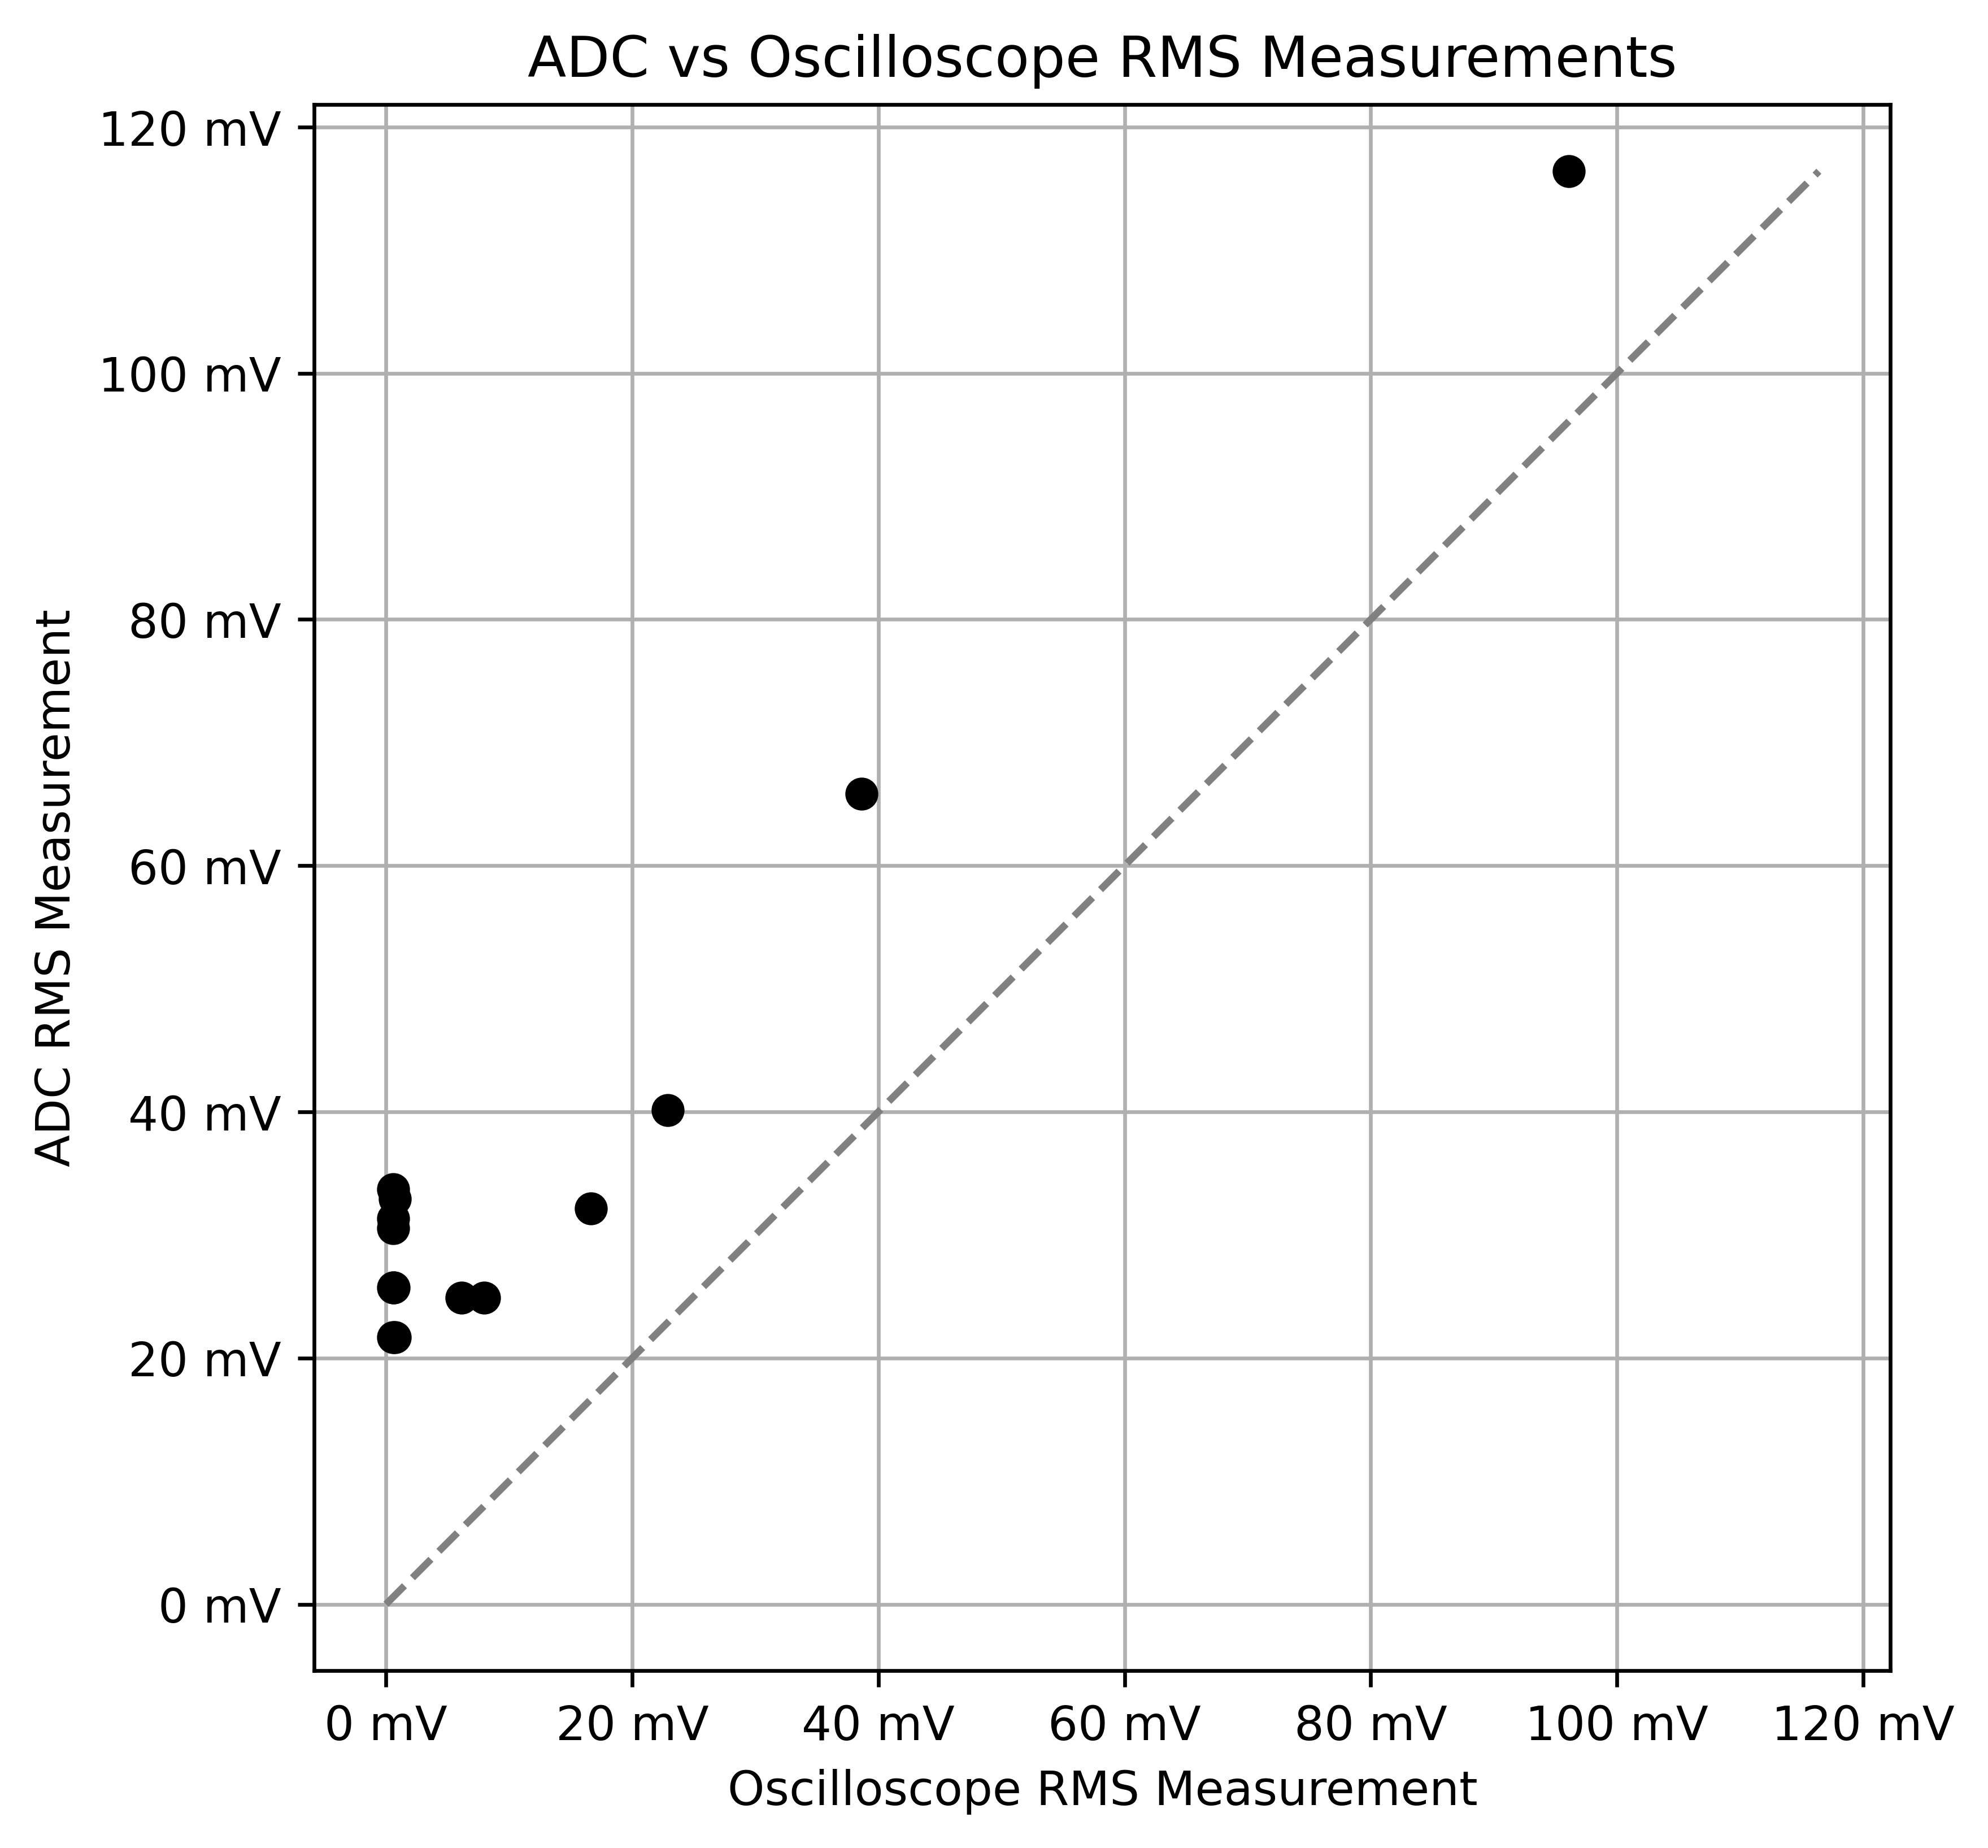

In [67]:
adc_rms_measured_values = [
    (
        get_adc_measurement(df, "Math1", RMS_MEAS_POINT)
        - get_adc_measurement(df, "Math1", RMS_NULL_MEAS_POINT)
    )
    for df in scope_dfs
]
osc_rms_measured_values = voltage_rms_values


def plot_adc_vs_oscilloscope_rms(
    adc_values: List[float], osc_values: List[float]
) -> Figure:
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot(
        osc_values,
        # adc_values / np.sqrt(2),
        adc_values,
        marker="o",
        linestyle="",
        color="black",
    )

    ax.plot(
        [0, max(max(adc_values), max(osc_values))],
        [0, max(max(osc_values), max(adc_values))],
        color="gray",
        linestyle="--",
    )

    ax.set_ylabel("ADC RMS Measurement")
    ax.set_xlabel("Oscilloscope RMS Measurement")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{1000*x:.0f} mV"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{1000*y:.0f} mV"))

    ax.set_aspect("equal", adjustable="datalim")

    ax.set_title("ADC vs Oscilloscope RMS Measurements")
    ax.grid(True)
    return fig


_ = plot_adc_vs_oscilloscope_rms(adc_rms_measured_values, osc_rms_measured_values)

In [68]:
def plot_voltage_current(df: pd.DataFrame) -> Figure:
    fig = plt.figure(figsize=(8, 18))
    gs = fig.add_gridspec(4, 1, hspace=0.15)

    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)
    ax3 = fig.add_subplot(gs[2, 0])
    ax4 = fig.add_subplot(gs[3, 0], sharex=ax3)

    axes = [ax1, ax2, ax3, ax4]

    TIME = df["Time(s)"]
    VOLTAGE = df["Channel2"]
    CURRENT = df["Channel1"]

    ax1.plot(
        TIME,
        CURRENT,
        label="Current",
        color="blue",
    )
    ax2.plot(
        TIME,
        VOLTAGE,
        label="Voltage",
        color="red",
    )

    ZOOM_PERIOD = (-0.001, 0.005)
    ZOOM_MASK = (TIME >= ZOOM_PERIOD[0]) & (TIME <= ZOOM_PERIOD[1])
    ax3.plot(
        TIME[ZOOM_MASK],
        CURRENT[ZOOM_MASK],
        label="Current",
        color="blue",
    )
    ax4.plot(
        TIME[ZOOM_MASK],
        VOLTAGE[ZOOM_MASK],
        label="Voltage",
        color="red",
    )
    for ax in [ax1, ax2]:
        for lim in ZOOM_PERIOD:
            ax.axvline(lim, color="gray", linestyle="--")

    phase_diff = calculate_phase_difference(df, PHASE_WINDOW)
    ax3.text(
        0.1,
        0.1,
        f"Phase Difference: {phase_diff:.2f} degrees",
        transform=ax3.transAxes,
        ha="left",
        va="center",
    )

    ax1.set_title("Instrumentation Amplifier Negative Output (Current)")
    ax2.set_title("Terminal Voltage (AC Coupled)")
    ax3.set_title("Zoomed Current")
    ax4.set_title("Zoomed Voltage")

    ax1.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.1f}V"))
    ax2.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{1000*y:.0f}mV"))
    ax3.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.1f}V"))
    ax4.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{1000*y:.0f}mV"))

    ax2.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.1f}s"))
    ax4.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{1000*x:.0f}ms"))

    return fig


VI_OUTPUT_DIR = os.path.join(PLOT_OUTPUT_DIR, "VI")
os.makedirs(VI_OUTPUT_DIR, exist_ok=True)


def save_voltage_current_plot(df: pd.DataFrame) -> None:
    fig = plot_voltage_current(df)
    fig.savefig(
        os.path.join(
            VI_OUTPUT_DIR,
            f"T{df.attrs['Test']}_C{df.attrs['Battery']}.png",
        ),
        bbox_inches="tight",
    )
    plt.close(fig)


with ThreadPoolExecutor() as executor:
    for df in scope_dfs:
        executor.submit(
            save_voltage_current_plot,
            df,
        )